# Fake-News Detection: Comparing Two Machine-Learning Models

**Research question:** On the ISOT dataset, how do Multinomial Naive Bayes and Logistic Regression compare using TF-IDF text features?

**Before you start:** Upload `Fake.csv` and `True.csv` when prompted. Run all cells in order. Do not report results until the notebook has run successfully.

## 1. Import libraries and upload dataset

In [1]:
import io
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

In [3]:
try:
    from google.colab import files
    import zipfile
    uploaded = files.upload()

    zip_name = next((name for name in uploaded if name.lower().endswith('.zip')), None)
    if zip_name:
        with zipfile.ZipFile(io.BytesIO(uploaded[zip_name]), 'r') as zip_ref:
            zip_ref.extractall('.')
        fake_df = pd.read_csv('Fake.csv')
        true_df = pd.read_csv('True.csv')
    else:
        fake_name = next(name for name in uploaded if name.lower().endswith("fake.csv"))
        true_name = next(name for name in uploaded if name.lower().endswith("true.csv"))
        fake_df = pd.read_csv(io.BytesIO(uploaded[fake_name]))
        true_df = pd.read_csv(io.BytesIO(uploaded[true_name]))
except (ImportError, StopIteration, FileNotFoundError):
    fake_df = pd.read_csv("data/Fake.csv")
    true_df = pd.read_csv("data/True.csv")

fake_df["label"] = "FAKE"
true_df["label"] = "REAL"
df = pd.concat([fake_df, true_df], ignore_index=True)

print("Combined shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())

Saving News-_dataset.zip to News-_dataset (1).zip
Combined shape: (44898, 5)

Columns: ['title', 'text', 'subject', 'date', 'label']


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",FAKE
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",FAKE
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",FAKE
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",FAKE
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",FAKE


## 2. Inspect labels and missing data

In [4]:
print("Label counts before cleaning:")
display(df["label"].value_counts().to_frame("count"))

print("Missing values in common text fields:")
for col in ["title", "text", "subject", "date"]:
    if col in df.columns:
        print(f"{col}: {df[col].isna().sum()}")

missing_text_cols = [c for c in ["title", "text"] if c not in df.columns]
if missing_text_cols:
    raise ValueError(f"Expected columns not found: {missing_text_cols}")

Label counts before cleaning:


,count
label,
FAKE,23481
REAL,21417


Missing values in common text fields:
title: 0
text: 0
subject: 0
date: 0


## 3. Clean the dataset

In [5]:
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)
df["content"] = (df["title"] + " " + df["text"]).str.lower()
df["content"] = df["content"].str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
df["content"] = df["content"].str.replace(r"\s+", " ", regex=True).str.strip()

before = len(df)
df = df[df["content"].str.len() > 0].copy()
after_empty = len(df)
df = df.drop_duplicates(subset=["content", "label"]).copy()
after_duplicates = len(df)

print(f"Rows originally: {before:,}")
print(f"Rows after removing empty text: {after_empty:,}")
print(f"Rows after removing duplicate text within each label: {after_duplicates:,}")
print("\nLabel counts after cleaning:")
display(df["label"].value_counts().to_frame("count"))

Rows originally: 44,898
Rows after removing empty text: 44,889
Rows after removing duplicate text within each label: 39,095

Label counts after cleaning:


,count
label,
REAL,21195
FAKE,17900


## 4. Check for possible dataset shortcuts

In [6]:
for term in ["reuters", "breaking", "read more", "featured image"]:
    contains = df["content"].str.contains(term, case=False, regex=False)
    rates = df.assign(has_term=contains).groupby("label")["has_term"].mean()
    print(f"\nTerm: {term!r}")
    display((rates * 100).round(2).to_frame("percent of class containing term"))

print("Interpret these patterns cautiously. They may reveal source/style shortcuts.")


Term: 'reuters'


,percent of class containing term
label,
FAKE,1.23
REAL,99.82



Term: 'breaking'


,percent of class containing term
label,
FAKE,6.59
REAL,1.80



Term: 'read more'


,percent of class containing term
label,
FAKE,9.53
REAL,0.04



Term: 'featured image'


,percent of class containing term
label,
FAKE,44.81
REAL,0.00


Interpret these patterns cautiously. They may reveal source/style shortcuts.


## 5. Split into training and test data

In [7]:
X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).round(3).to_frame("proportion"))

Training samples: 31276
Testing samples: 7819

Training class proportions:


,proportion
label,
REAL,0.542
FAKE,0.458


## 6. Convert text into TF-IDF features

In [8]:
vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    strip_accents="unicode"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF matrix:", X_train_tfidf.shape)
print("Test TF-IDF matrix:", X_test_tfidf.shape)

Training TF-IDF matrix: (31276, 30000)
Test TF-IDF matrix: (7819, 30000)


## 7. Train two models and evaluate them

In [9]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    predictions[name] = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0)
    })

    print("\n" + "=" * 65)
    print(name)
    print(classification_report(y_test, pred, zero_division=0))

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
display(results_df.round(4))


Multinomial Naive Bayes
              precision    recall  f1-score   support

        FAKE       0.95      0.95      0.95      3580
        REAL       0.95      0.96      0.96      4239

    accuracy                           0.95      7819
   macro avg       0.95      0.95      0.95      7819
weighted avg       0.95      0.95      0.95      7819


Logistic Regression
              precision    recall  f1-score   support

        FAKE       0.99      0.98      0.99      3580
        REAL       0.99      0.99      0.99      4239

    accuracy                           0.99      7819
   macro avg       0.99      0.99      0.99      7819
weighted avg       0.99      0.99      0.99      7819



,Model,Accuracy,Macro precision,Macro recall,Macro F1
1,Logistic Regression,0.9877,0.9880,0.9873,0.9876
0,Multinomial Naive Bayes,0.9538,0.9538,0.9532,0.9535


## 8. Confusion matrices

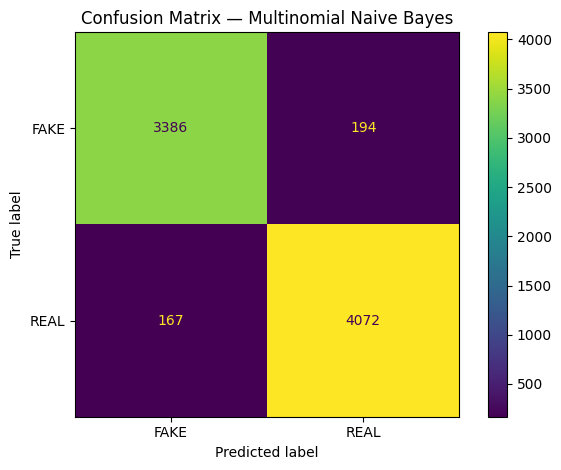

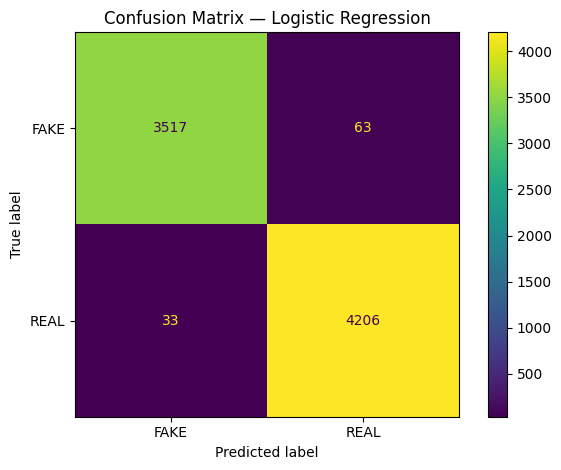

In [10]:
for name, pred in predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=["FAKE", "REAL"], values_format="d"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 9. Compare results

In [11]:
best_row = results_df.iloc[0]
print(f"Highest macro F1 in this run: {best_row['Model']}")
print(f"Macro F1: {best_row['Macro F1']:.4f}")
print("\nFull comparison:")
display(results_df.round(4))

Highest macro F1 in this run: Logistic Regression
Macro F1: 0.9876

Full comparison:


,Model,Accuracy,Macro precision,Macro recall,Macro F1
1,Logistic Regression,0.9877,0.9880,0.9873,0.9876
0,Multinomial Naive Bayes,0.9538,0.9538,0.9532,0.9535


### Findings and Future Improvements

The experiment compared Multinomial Naive Bayes and Logistic Regression for fake-news detection. Logistic Regression performed better, achieving 98.77% accuracy, compared with 95.38% for Naive Bayes. Future improvements include testing more models, tuning parameters, and evaluating newer news datasets to improve reliability.
